In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from deep_isochron.analysis.ode import find_limit_cycle, floquet
from deep_isochron.data import (
    resolve_device,
)
from deep_isochron.plotting import configure_rcparams
from deep_isochron.systems import FitzhughNagumo


jax.config.update("jax_enable_x64", True)
device = resolve_device(
    3
)  # the card the scheduler assigned; refuses to guess on a shared node
jax.config.update("jax_default_device", device)
configure_rcparams()

# The limit cycle of FitzHugh–Nagumo and its Floquet multipliers

O1 (`find_limit_cycle`) and O2 (`floquet`); the prototyping code that preceded them lives in `tests/test_analysis_ode.py` and `analysis/ode/floquet.py`.

In [2]:
ode = FitzhughNagumo()
cycle = find_limit_cycle(ode, jnp.asarray([3.0, 3.0]), t_settle=10.0, m=10)
cycle.period, cycle.orientation()

E1028 12:27:17.566285  800046 cuda_executor.cc:1348] [3] Failed to allocate device memory of 23.80GiB (25555894272 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla+/xla/stream_executor/cuda/cuda_status.cc:45
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:226
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:389



(Array(11.22788676, dtype=float64), -1)

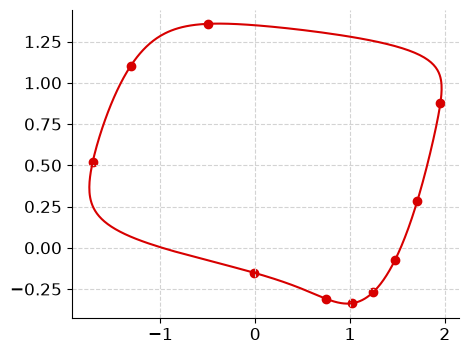

In [3]:
times, points = cycle.sample(512)
fig, ax = plt.subplots(1, 1, figsize=(5, 4))
ax.plot(*points.T)
ax.scatter(*cycle.x0s.T)

In [4]:
for method in ("periodic_schur", "monodromy", "liouville"):
    fl = floquet(cycle, method=method)
    print(method, fl.multipliers, fl.exponents, fl.trivial_error, fl.closure)

periodic_schur [1.00000000e+00 1.69059036e-12] [ 5.39080812e-11 -2.41416251e+00] 6.05273831055797e-10 2.6581664292158038e-11
monodromy [1.00000000e+00 1.69042558e-12] [ 5.31331915e-11 -2.41417119e+00] 5.965734573010195e-10 None
liouville [1.00000000e+00 1.69059036e-12] [ 0.         -2.41416251] None None


# The asymptotic phase fields of fhn and fhn-easy

O3 by forward integration and a read-off on the cycle (`phase_grid`, route (a) of
`docs/design/analysis.md` §4). The cycle and phase 0 come from the isochron configs
(`isochron_cycle`), so the field, the AUTO isochrons and the model are compared on one
phase origin; `t_end` is the config's `phase_field.t_end`. Masked points are those
whose two readings, one period apart, differ by 1e-6 or more, or whose orbit has not
come within 1e-6 of the cycle: near the source, and wherever `t_end` falls short.
Run under float64 (first cell); on two CPU cores a 200 × 200 grid takes about a
minute per system.

In [5]:
import time
from pathlib import Path

import numpy as np
from deep_isochron.analysis.ode import asymptotic_phase, phase_grid
from deep_isochron.experiment.isochrons import (
    isochron_cycle,
    isochron_file,
    load_isochrons,
)
from hydra import compose, initialize_config_dir


def isochron_config(name):
    with initialize_config_dir(
        config_dir=str(Path("configs").resolve()), version_base=None
    ):
        return compose(config_name=f"isochrons/{name}")


xs = ys = jnp.linspace(-3.0, 3.0, 200)
fields = {}
for name in ("fhn", "fhn-easy"):
    cfg = isochron_config(name)
    cycle = isochron_cycle(cfg)
    start = time.perf_counter()
    field, mask, result = phase_grid(cycle, xs, ys, t_end=cfg.phase_field.t_end)

    fields[name] = (cfg, cycle, np.asarray(field), np.asarray(mask), result)
    print(
        f"{name}: T = {float(cycle.period):.6f}, masked {int((~mask).sum())} of "
        f"{mask.size}, {time.perf_counter() - start:.0f} s"
    )

fhn: T = 11.227887, masked 0 of 40000, 238 s
fhn-easy: T = 10.832945, masked 0 of 40000, 285 s


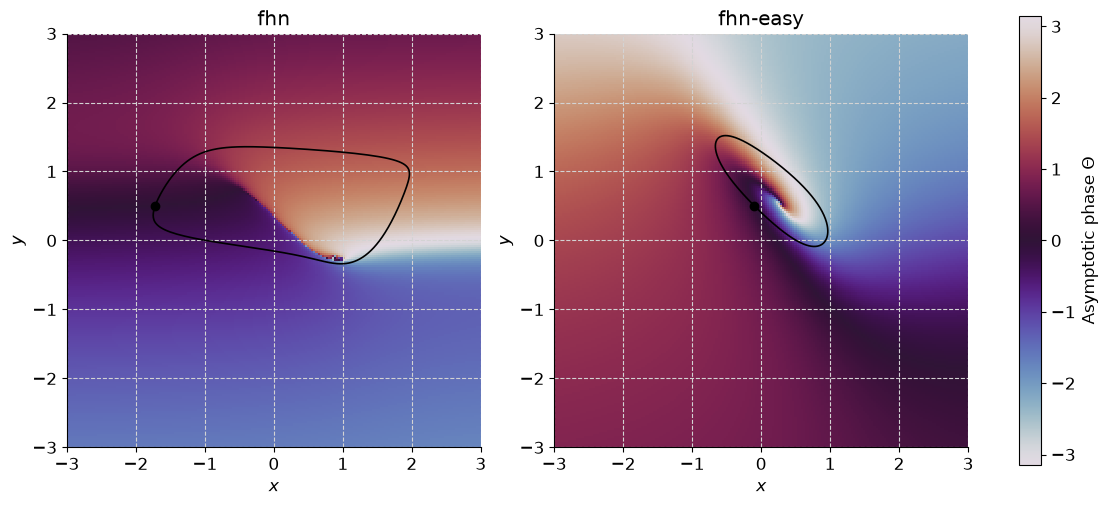

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for ax, (name, (cfg, cycle, field, mask, _)) in zip(axes, fields.items(), strict=True):
    ax.set_facecolor("0.6")  # masked points
    image = ax.pcolormesh(
        xs, ys, field, cmap="twilight", vmin=-np.pi, vmax=np.pi, shading="nearest"
    )
    if isochron_file(cfg).exists():
        for iso in load_isochrons(cfg).isochrons[::10]:
            ax.plot(*iso.points.T, color="w", lw=0.6)
    _, points = cycle.sample(512)
    ax.plot(*np.asarray(points).T, color="k", lw=1.2)
    ax.plot(*np.asarray(cycle.x0s[0]), "ko")
    ax.set(title=name, xlabel="$x$", ylabel="$y$", aspect="equal")
    ax.set(xlim=(xs[0], xs[-1]), ylim=(ys[0], ys[-1]))
fig.colorbar(image, ax=axes, label=r"Asymptotic phase $\Theta$")

Check against AUTO (when the config's `.nc` exists): the phase at the points of each
isochron within 0.01 of the cycle, against the isochron's phase. Farther out, near the
source, a stored point's position error times the steep phase gradient there grows
to a radian (`tests/test_phase.py`).

In [ ]:
for name, (cfg, cycle, *_) in fields.items():
    if not isochron_file(cfg).exists():
        print(f"{name}: no isochron file at {isochron_file(cfg)}")
        continue
    _, samples = cycle.sample(4096)
    read = jax.jit(
        jax.vmap(lambda x: asymptotic_phase(cycle, x, t_end=cfg.phase_field.t_end))
    )
    gaps = []
    for iso in load_isochrons(cfg).isochrons:
        d = np.linalg.norm(iso.points[:, None] - np.asarray(samples)[None], axis=2)
        near = iso.points[d.min(axis=1) < 0.01]
        if len(near):
            phase = np.asarray(read(jnp.asarray(near)).phase)
            gaps.append(np.abs(np.angle(np.exp(1j * (phase - iso.phase)))).max())
    print(f"{name}: {len(gaps)} isochrons, largest gap {max(gaps):.2e} rad")

Comparison with a trained model. Fill in the run directories. A model's phase has its
own origin and may run either way round the cycle, so the reference is aligned to it
by a circular-mean offset for each direction, and the direction with the smaller
residual is kept. `load_model` applies the run's own `x64` and device settings, so the
reference fields above are computed first and kept as NumPy arrays.

fhn: sense -1, offset -2.3996 rad, residual rms 8.360e-02, max 3.060e+00 rad
fhn-easy: sense -1, offset -0.4238 rad, residual rms 1.094e-01, max 3.037e+00 rad


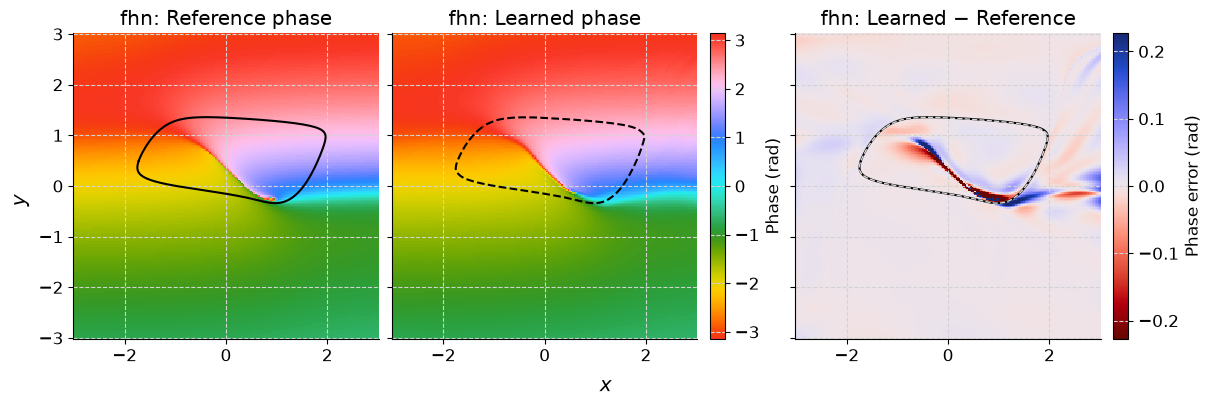

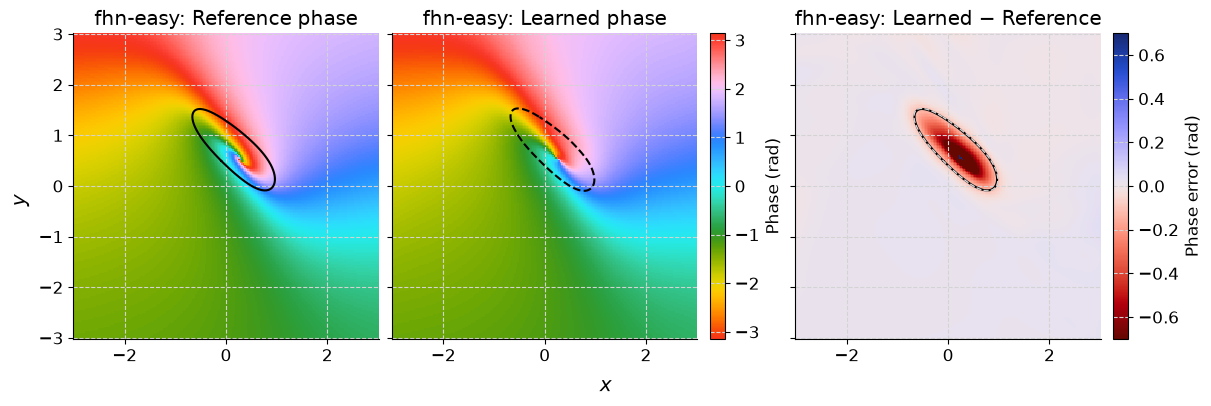

In [29]:
import colorcet as cc
from deep_isochron.experiment.run import load_model


RUN_DIRS = {
    "fhn": "./runs/fhn2",
    "fhn-easy": "./runs/fhn_easy",
}  # the run directories of the trained models


def wrap(angle):
    return np.angle(np.exp(1j * angle))


def align(model_phase, reference):
    """(sense, offset, residual) with model ≈ sense · reference + offset."""
    best = None
    for sense in (1.0, -1.0):
        offset = np.angle(np.nanmean(np.exp(1j * (model_phase - sense * reference))))
        residual = wrap(model_phase - sense * reference - offset)
        rms = np.sqrt(np.nanmean(residual**2))
        if best is None or rms < best[3]:
            best = (sense, offset, residual, rms)
    return best


grid = np.stack(np.meshgrid(np.asarray(xs), np.asarray(ys)), axis=-1).reshape(-1, 2)
for name, run_dir in RUN_DIRS.items():
    if run_dir is None:
        continue
    cfg, cycle, field, mask, _ = fields[name]
    model = load_model(run_dir)
    model_phase = np.asarray(jax.vmap(model.phase)(jnp.asarray(grid)))
    model_phase = model_phase.reshape(field.shape)
    sense, offset, residual, rms = align(model_phase, field)
    print(
        f"{name}: sense {sense:+.0f}, offset {offset:.4f} rad, residual rms {rms:.3e}, "
        f"max {np.nanmax(np.abs(residual)):.3e} rad"
    )
    fig, axes = plt.subplots(
        1, 3, figsize=(12, 4), constrained_layout=True, sharey=True
    )
    panels = (
        ("Reference phase", wrap(sense * field + offset), cc.cm.CET_C6, np.pi),
        ("Learned phase", np.where(mask, model_phase, np.nan), cc.cm.CET_C6, np.pi),
        (
            "Learned − Reference",
            residual,
            cc.cm.CET_D1A_r,
            np.nanpercentile(np.abs(residual), 99.5),
        ),
    )
    images = []
    for ax, (title, data, cmap, limit) in zip(axes, panels, strict=True):
        ax.set_facecolor("0.6")
        img = ax.pcolormesh(
            xs, ys, data, cmap=cmap, vmin=-limit, vmax=limit, shading="nearest"
        )
        images.append(img)
        ax.set(title=f"{name}: {title}", aspect="equal")

    # Plot true limit cycle
    _, points = cycle.sample(512)
    axes[0].plot(*np.asarray(points).T, color="k", lw=1.5)

    # Plot learned limit cycle
    pts_learned = jax.vmap(model.cycle_point)(
        jnp.linspace(-jnp.pi, jnp.pi, 512, endpoint=False)
    )
    axes[1].plot(*np.asarray(pts_learned).T, color="k", lw=1.5, ls="--")

    # Plot both cycles on the residual panel
    axes[2].plot(*np.asarray(points).T, color="k", lw=1.5)
    axes[2].plot(*np.asarray(pts_learned).T, color="lightgrey", lw=1.0, ls="--")

    cax_phase = axes[1].inset_axes([1.04, 0, 0.05, 1])
    cax_residual = axes[2].inset_axes([1.04, 0, 0.05, 1])
    cbar_phase = fig.colorbar(
        images[0],
        ax=axes[:2],
        cax=cax_phase,
    )
    cbar_phase.set_label(label="Phase (rad)", fontsize="medium")
    cbar_residual = fig.colorbar(
        images[2],
        ax=axes[2],
        cax=cax_residual,
    )
    cbar_residual.set_label(label="Phase error (rad)", fontsize="medium")

    if isochron_file(cfg).exists():  # an isochron is a level set of the model's phase
        spreads = []
        for iso in load_isochrons(cfg).isochrons:
            phase = np.asarray(jax.vmap(model.phase)(jnp.asarray(iso.points)))
            spreads.append(np.abs(wrap(phase - sense * iso.phase - offset)).max())
        print(
            f"  on the AUTO isochrons: median gap {np.median(spreads):.3e}, "
            f"max {max(spreads):.3e} rad"
        )

    fig.supxlabel("$x$")
    fig.supylabel("$y$")